<a href="https://colab.research.google.com/github/David172-svg/recomendador-cinco-enfoques-ml/blob/main/Semana12_Recomendacion_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conectar Google Colab con nuestro proyecto de GitHub


In [1]:

!git clone https://github.com/David172-svg/recomendador-cinco-enfoques-ml.git
%cd /content/recomendador-cinco-enfoques-ml

Cloning into 'recomendador-cinco-enfoques-ml'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 17 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 12.54 KiB | 2.51 MiB/s, done.
/content/recomendador-cinco-enfoques-ml


# Instalación de las bibliotecas necesarias

In [2]:
# Instalar las bibliotecas necesarias para Machine Learning

!pip install -q -r requirements.txt

# Verificar las bibliotecas instaladas
import numpy as np
import sklearn

print("Bibliotecas instaladas correctamente.")
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Bibliotecas instaladas correctamente.
NumPy: 2.4.6
Scikit-learn: 1.6.1


#Carga y exploración de los datos desde GitHub

In [3]:
# Cargar el catálogo de películas desde el proyecto de GitHub

import pandas as pd
from src.datos import cargar_catalogo, generar_interacciones, USUARIOS

# Cargar las películas
catalogo = cargar_catalogo()

# Generar las interacciones simuladas
interacciones = generar_interacciones(catalogo)

# Convertir los datos en tablas
df_peliculas = pd.read_csv("data/catalogo_peliculas.csv")
df_interacciones = pd.DataFrame(interacciones)

# Guardar las interacciones en un archivo CSV
df_interacciones.to_csv("data/interacciones_simuladas.csv", index=False)

# Mostrar información general
print("=== DATOS DE LA PLATAFORMA STREAMPLUS ===")
print("Total de películas:", len(catalogo))
print("Total de usuarios:", len(USUARIOS))
print("Total de interacciones:", len(interacciones))

print("\n=== PRIMERAS 5 PELÍCULAS ===")
display(df_peliculas.head())

print("\n=== PRIMERAS 5 INTERACCIONES ===")
display(df_interacciones.head())

=== DATOS DE LA PLATAFORMA STREAMPLUS ===
Total de películas: 32
Total de usuarios: 12
Total de interacciones: 204

=== PRIMERAS 5 PELÍCULAS ===


,id,titulo,generos
0,1,Órbita perdida,Ciencia ficción|Suspenso
1,2,Código Aurora,Ciencia ficción|Acción
2,3,El último cohete,Ciencia ficción|Drama
3,4,Misión Titán,Ciencia ficción|Acción
4,5,Un futuro cerca,Ciencia ficción|Romance



=== PRIMERAS 5 INTERACCIONES ===


,usuario,pelicula_id,me_gusta
0,ana,2,1
1,ana,6,1
2,ana,13,0
3,ana,9,1
4,ana,25,0


#Distribución de películas según su género

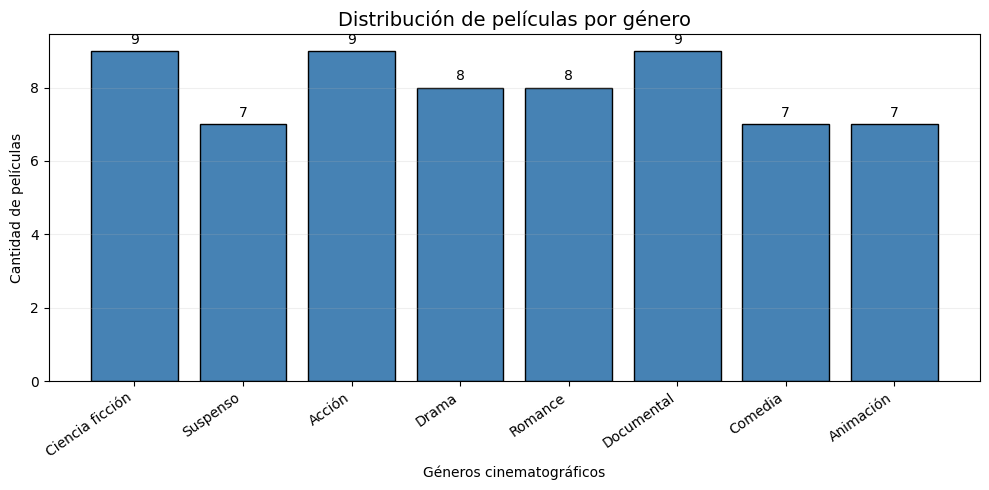

In [4]:
# Gráfico de distribución de películas por género

import matplotlib.pyplot as plt
from collections import Counter

# Obtener los géneros de todas las películas
generos = []

for pelicula in catalogo:
    generos.extend(pelicula["generos"])

# Contar cuántas películas pertenecen a cada género
conteo = Counter(generos)

# Crear el gráfico
plt.figure(figsize=(10, 5))

barras = plt.bar(
    conteo.keys(),
    conteo.values(),
    color="steelblue",
    edgecolor="black"
)

# Agregar los valores encima de las barras
plt.bar_label(barras, padding=3)

plt.title("Distribución de películas por género", fontsize=14)
plt.xlabel("Géneros cinematográficos")
plt.ylabel("Cantidad de películas")

plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Guardar el gráfico como imagen
plt.savefig("distribucion_generos.png", dpi=200)

plt.show()

#Objetivo: Predecir qué películas podrían gustarle a un usuario según sus preferencias anteriores.

In [6]:
# APRENDIZAJE SUPERVISADO
# Algoritmo: Regresión logística

from src.metodos import supervisado

# Entrenar el modelo y obtener recomendaciones para Ana
resultado_sup = supervisado(catalogo, interacciones, "ana")

# Mostrar los resultados
print("=== APRENDIZAJE SUPERVISADO ===")

print("\nAlgoritmo utilizado:")
print(resultado_sup["algoritmo"])

print("\nResultado del modelo:")
print(resultado_sup["metrica"])

print("\nPelículas recomendadas para Ana:")

for i, (titulo, probabilidad) in enumerate(
    resultado_sup["recomendaciones"], start=1
):
    print(f"{i}. {titulo} - Probabilidad: {probabilidad:.1%}")

=== APRENDIZAJE SUPERVISADO ===

Algoritmo utilizado:
Regresión logística

Resultado del modelo:
Exactitud en datos reservados: 62.75%

Películas recomendadas para Ana:
1. Un futuro cerca - Probabilidad: 62.1%
2. El concurso - Probabilidad: 61.4%
3. La gran persecución - Probabilidad: 58.8%


#Gráfico del aprendizaje supervisado

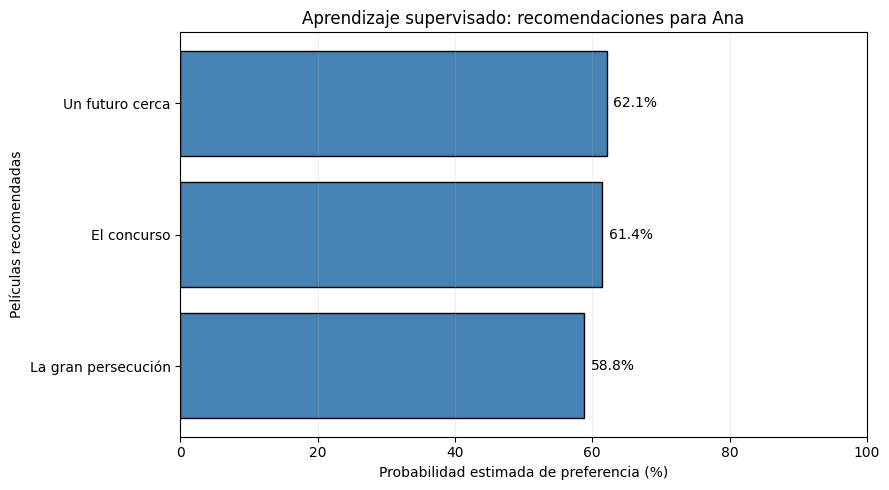

In [7]:
# Gráfico de resultados del aprendizaje supervisado

import matplotlib.pyplot as plt

# Obtener las películas y sus probabilidades
peliculas = [
    titulo for titulo, prob in resultado_sup["recomendaciones"]
]

probabilidades = [
    prob * 100 for titulo, prob in resultado_sup["recomendaciones"]
]

# Crear el gráfico
plt.figure(figsize=(9, 5))

barras = plt.barh(
    peliculas[::-1],
    probabilidades[::-1],
    color="steelblue",
    edgecolor="black"
)

# Mostrar el porcentaje en cada barra
for barra in barras:
    plt.text(
        barra.get_width() + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{barra.get_width():.1f}%",
        va="center"
    )

plt.title("Aprendizaje supervisado: recomendaciones para Ana")
plt.xlabel("Probabilidad estimada de preferencia (%)")
plt.ylabel("Películas recomendadas")
plt.xlim(0, 100)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

# Guardar el gráfico
plt.savefig("grafico_supervisado.png", dpi=200)

plt.show()

#Aprendizaje no supervisado

In [8]:
# APRENDIZAJE NO SUPERVISADO
# Algoritmo: K-Means

from src.metodos import no_supervisado

# Aplicar K-Means para agrupar usuarios
resultado_no_sup = no_supervisado(catalogo, interacciones, "ana")

# Mostrar los resultados
print("=== APRENDIZAJE NO SUPERVISADO ===")

print("\nAlgoritmo utilizado:")
print(resultado_no_sup["algoritmo"])

print("\nAgrupación de usuarios:")
print(resultado_no_sup["metrica"])

print("\nPelículas recomendadas para Ana:")

for i, (titulo, puntaje) in enumerate(
    resultado_no_sup["recomendaciones"], start=1
):
    print(f"{i}. {titulo} - Puntaje: {puntaje:.3f}")

=== APRENDIZAJE NO SUPERVISADO ===

Algoritmo utilizado:
K-Means (3 grupos)

Agrupación de usuarios:
Usuarios del mismo grupo: ana, felipe, jorge, luis

Películas recomendadas para Ana:
1. La gran persecución - Puntaje: 2.175
2. Pasos perdidos - Puntaje: 2.175
3. El bosque brillante - Puntaje: 1.175


#Gráfico de agrupación con K-Means

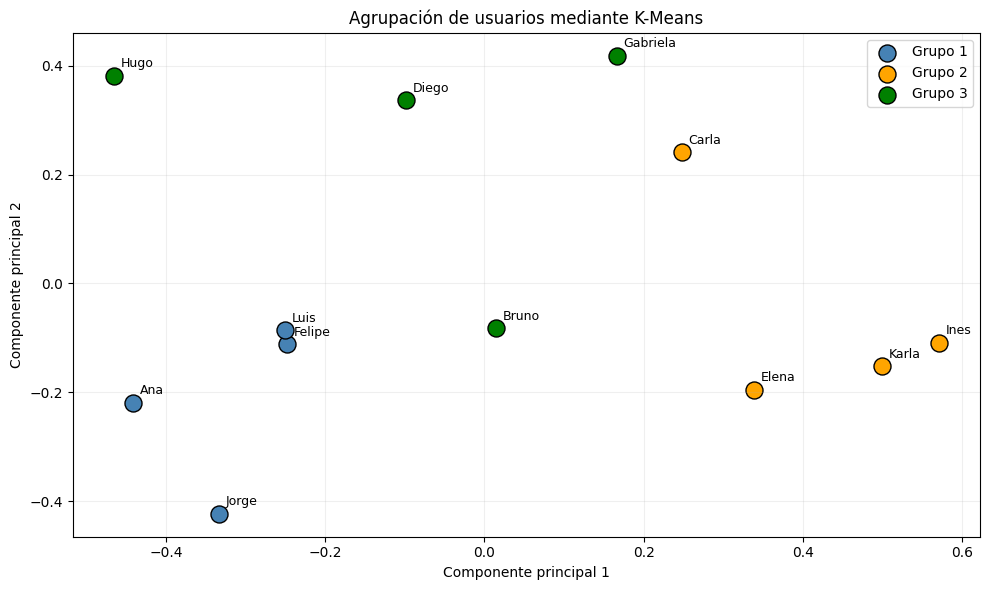

In [9]:
# GRÁFICO DEL APRENDIZAJE NO SUPERVISADO
# Agrupación de usuarios mediante K-Means

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from src.datos import lista_generos, matriz_generos, USUARIOS

# Preparar los perfiles de los usuarios
nombres = list(USUARIOS.keys())
generos_ml = lista_generos(catalogo)
indice = {p["id"]: p for p in catalogo}

perfiles = []

for usuario in nombres:
    favoritas = [
        indice[r["pelicula_id"]]
        for r in interacciones
        if r["usuario"] == usuario and r["me_gusta"] == 1
    ]

    if favoritas:
        perfil = matriz_generos(favoritas, generos_ml).mean(axis=0)
    else:
        perfil = np.zeros(len(generos_ml))

    perfiles.append(perfil)

X = np.array(perfiles)

# Agrupar los usuarios con K-Means
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

grupos = modelo_kmeans.fit_predict(X)

# Reducir los datos a dos dimensiones para visualizarlos
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X)

# Crear el gráfico
plt.figure(figsize=(10, 6))

colores = ["steelblue", "orange", "green"]

for grupo in range(3):
    seleccion = grupos == grupo

    plt.scatter(
        coordenadas[seleccion, 0],
        coordenadas[seleccion, 1],
        color=colores[grupo],
        s=150,
        edgecolor="black",
        label=f"Grupo {grupo + 1}"
    )

# Colocar los nombres de los usuarios
for i, nombre in enumerate(nombres):
    plt.annotate(
        nombre.capitalize(),
        (coordenadas[i, 0], coordenadas[i, 1]),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Agrupación de usuarios mediante K-Means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

# Guardar el gráfico
plt.savefig("grafico_kmeans.png", dpi=200)

plt.show()

#Aprendizaje semisupervisado

In [10]:
# APRENDIZAJE SEMISUPERVISADO
# Algoritmo: SelfTrainingClassifier

from src.metodos import semisupervisado

# Entrenar el modelo semisupervisado
resultado_semi = semisupervisado(
    catalogo,
    interacciones,
    "ana"
)

# Mostrar los resultados
print("=== APRENDIZAJE SEMISUPERVISADO ===")

print("\nAlgoritmo utilizado:")
print(resultado_semi["algoritmo"])

print("\nResultados del entrenamiento:")
print(resultado_semi["metrica"])

print("\nPelículas recomendadas para Ana:")

for i, (titulo, probabilidad) in enumerate(
    resultado_semi["recomendaciones"], start=1
):
    print(
        f"{i}. {titulo} - "
        f"Probabilidad: {probabilidad:.1%}"
    )

=== APRENDIZAJE SEMISUPERVISADO ===

Algoritmo utilizado:
Autoentrenamiento (SelfTrainingClassifier + Regresión logística)

Resultados del entrenamiento:
Etiquetas iniciales: 51; pseudoetiquetas añadidas: 120

Películas recomendadas para Ana:
1. El concurso - Probabilidad: 97.8%
2. La última estación - Probabilidad: 94.4%
3. El lado oculto - Probabilidad: 94.1%


#Gráfico del aprendizaje semisupervisado

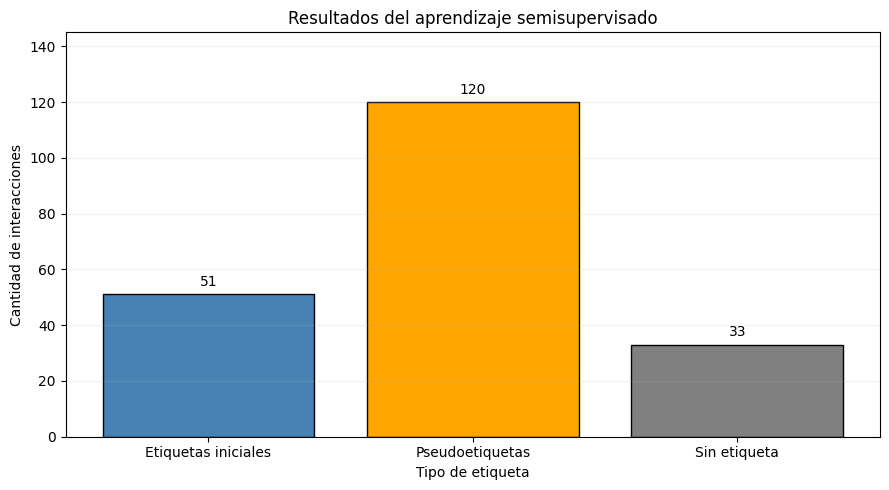

In [11]:
# GRÁFICO DEL APRENDIZAJE SEMISUPERVISADO
# Comparación de etiquetas y pseudoetiquetas

import matplotlib.pyplot as plt
import re

# Obtener los valores del resultado del modelo
valores = re.findall(r"\d+", resultado_semi["metrica"])

etiquetas_iniciales = int(valores[0])
pseudoetiquetas = int(valores[1])

# Calcular los registros que permanecen sin etiqueta
sin_etiquetar = (
    len(interacciones)
    - etiquetas_iniciales
    - pseudoetiquetas
)

# Preparar los datos del gráfico
categorias = [
    "Etiquetas iniciales",
    "Pseudoetiquetas",
    "Sin etiqueta"
]

cantidades = [
    etiquetas_iniciales,
    pseudoetiquetas,
    sin_etiquetar
]

# Crear el gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(
    categorias,
    cantidades,
    color=["steelblue", "orange", "gray"],
    edgecolor="black"
)

# Mostrar los valores encima de las barras
plt.bar_label(barras, padding=4)

plt.title("Resultados del aprendizaje semisupervisado")
plt.xlabel("Tipo de etiqueta")
plt.ylabel("Cantidad de interacciones")
plt.ylim(0, max(cantidades) + 25)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Guardar el gráfico
plt.savefig("grafico_semisupervisado.png", dpi=200)

plt.show()

#Aprendizaje autosupervisado

In [12]:
# APRENDIZAJE AUTOSUPERVISADO
# Algoritmo: Reconstrucción de características con Ridge

from src.metodos import autosupervisado

# Entrenar el modelo autosupervisado
resultado_auto = autosupervisado(
    catalogo,
    interacciones,
    "ana"
)

# Mostrar los resultados
print("=== APRENDIZAJE AUTOSUPERVISADO ===")

print("\nAlgoritmo utilizado:")
print(resultado_auto["algoritmo"])

print("\nResultado del entrenamiento:")
print(resultado_auto["metrica"])

print("\nPelículas recomendadas para Ana:")

for i, (titulo, similitud) in enumerate(
    resultado_auto["recomendaciones"], start=1
):
    print(
        f"{i}. {titulo} - "
        f"Similitud: {similitud:.3f}"
    )

=== APRENDIZAJE AUTOSUPERVISADO ===

Algoritmo utilizado:
Reconstrucción de datos enmascarados + Ridge

Resultado del entrenamiento:
Error cuadrático de reconstrucción: 0.0708 (en entrenamiento)

Películas recomendadas para Ana:
1. La gran persecución - Similitud: 0.614
2. Pasos perdidos - Similitud: 0.614
3. El bosque brillante - Similitud: 0.565


#Gráfico del aprendizaje autosupervisado

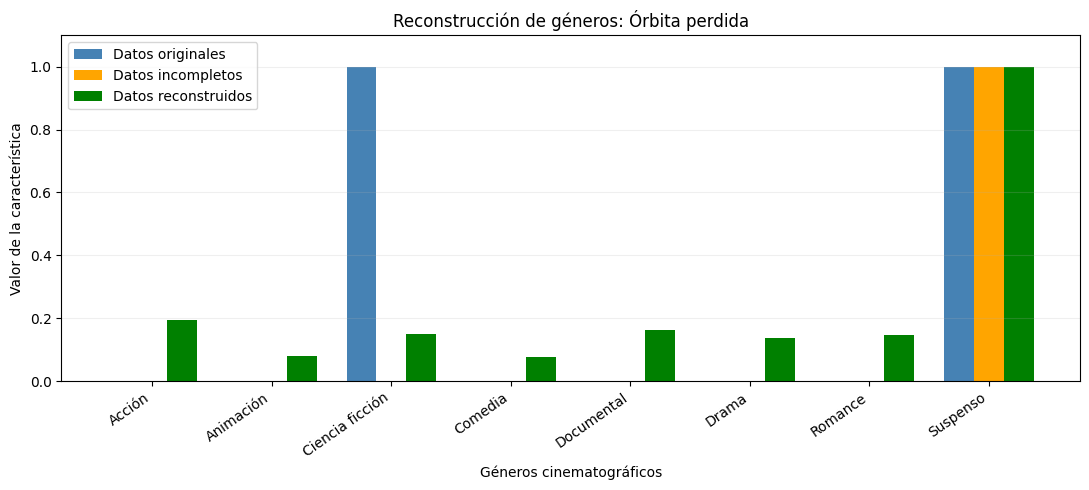

In [13]:
# GRÁFICO DEL APRENDIZAJE AUTOSUPERVISADO
# Reconstrucción de géneros ocultos mediante Ridge

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from src.datos import lista_generos, matriz_generos

# Obtener las características de las películas
nombres_generos = lista_generos(catalogo)
matriz = matriz_generos(catalogo, nombres_generos)

# Crear ejemplos con información ocultada
rng = np.random.default_rng(321)

entradas = []
objetivos = []

for fila in matriz:
    for _ in range(18):
        mascara = rng.random(len(fila)) > 0.35
        entradas.append(fila * mascara)
        objetivos.append(fila)

# Entrenar el modelo de reconstrucción
modelo_ridge = Ridge(alpha=1.0)

modelo_ridge.fit(
    np.array(entradas),
    np.array(objetivos)
)

# Seleccionar una película de ejemplo
pelicula = catalogo[0]

original = matriz[0].copy()
incompleto = original.copy()

# Ocultar uno de sus géneros
indice_oculto = np.where(original == 1)[0][0]
incompleto[indice_oculto] = 0

# Reconstruir la información
reconstruido = modelo_ridge.predict(
    incompleto.reshape(1, -1)
)[0]

reconstruido = np.clip(reconstruido, 0, 1)

# Preparar el gráfico
x = np.arange(len(nombres_generos))
ancho = 0.25

plt.figure(figsize=(11, 5))

plt.bar(
    x - ancho, original, ancho,
    label="Datos originales", color="steelblue"
)

plt.bar(
    x, incompleto, ancho,
    label="Datos incompletos", color="orange"
)

plt.bar(
    x + ancho, reconstruido, ancho,
    label="Datos reconstruidos", color="green"
)

plt.title(
    f"Reconstrucción de géneros: {pelicula['titulo']}"
)

plt.xlabel("Géneros cinematográficos")
plt.ylabel("Valor de la característica")

plt.xticks(x, nombres_generos, rotation=35, ha="right")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Guardar el gráfico
plt.savefig("grafico_autosupervisado.png", dpi=200)

plt.show()

#Aprendizaje por refuerzo

In [14]:
# APRENDIZAJE POR REFUERZO
# Algoritmo: Epsilon-Greedy

from src.metodos import por_refuerzo

# Ejecutar el aprendizaje por refuerzo
resultado_refuerzo = por_refuerzo(
    catalogo,
    interacciones,
    "ana"
)

# Mostrar los resultados
print("=== APRENDIZAJE POR REFUERZO ===")

print("\nAlgoritmo utilizado:")
print(resultado_refuerzo["algoritmo"])

print("\nResultados del entrenamiento:")
print(resultado_refuerzo["metrica"])

print("\nPelículas recomendadas para Ana:")

for i, (titulo, _) in enumerate(
    resultado_refuerzo["recomendaciones"], start=1
):
    print(f"{i}. {titulo}")

=== APRENDIZAJE POR REFUERZO ===

Algoritmo utilizado:
Bandido de varios brazos con epsilon-greedy (ε = 0.20)

Resultados del entrenamiento:
Tras 200 rondas simuladas: 146 clics; mejor género aprendido: Acción

Películas recomendadas para Ana:
1. La gran persecución
2. Correr para vivir
3. Pasos perdidos


#Gráfico del aprendizaje por refuerzo

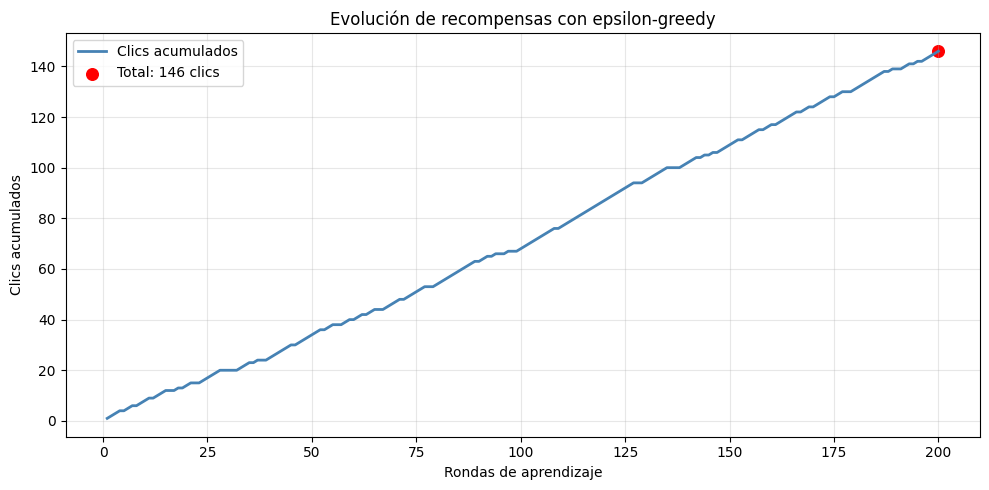

Total de clics: 146


In [15]:
# GRÁFICO DEL APRENDIZAJE POR REFUERZO
# Evolución de recompensas con epsilon-greedy

import numpy as np
import matplotlib.pyplot as plt
from src.datos import lista_generos, USUARIOS

# Preparar la simulación
generos_ref = lista_generos(catalogo)
rng = np.random.default_rng(789)

intentos = np.zeros(len(generos_ref), dtype=int)
promedios = np.zeros(len(generos_ref))

clics_por_ronda = []

# Ejecutar 200 rondas
for ronda in range(200):

    # Explorar o aprovechar
    if rng.random() < 0.20:
        accion = int(rng.integers(len(generos_ref)))
    else:
        mejores = np.flatnonzero(
            promedios == promedios.max()
        )
        accion = int(rng.choice(mejores))

    # Simular la respuesta del usuario
    if generos_ref[accion] in USUARIOS["ana"]:
        probabilidad = 0.80
    else:
        probabilidad = 0.15

    clic = int(rng.random() < probabilidad)

    # Actualizar las recompensas
    intentos[accion] += 1
    promedios[accion] += (
        clic - promedios[accion]
    ) / intentos[accion]

    clics_por_ronda.append(clic)

# Calcular los clics acumulados
clics_acumulados = np.cumsum(clics_por_ronda)

# Crear el gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 201),
    clics_acumulados,
    color="steelblue",
    linewidth=2,
    label="Clics acumulados"
)

plt.scatter(
    200,
    clics_acumulados[-1],
    color="red",
    s=70,
    label=f"Total: {clics_acumulados[-1]} clics"
)

plt.title("Evolución de recompensas con epsilon-greedy")
plt.xlabel("Rondas de aprendizaje")
plt.ylabel("Clics acumulados")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Guardar el gráfico
plt.savefig("grafico_refuerzo.png", dpi=200)

plt.show()

print("Total de clics:", clics_acumulados[-1])

#Comparación de los cinco algoritmos

In [16]:
# COMPARACIÓN DE LOS CINCO ENFOQUES DE MACHINE LEARNING

import pandas as pd

# Reunir los resultados obtenidos
resultados_ml = [
    ("Supervisado", resultado_sup),
    ("No supervisado", resultado_no_sup),
    ("Semisupervisado", resultado_semi),
    ("Autosupervisado", resultado_auto),
    ("Por refuerzo", resultado_refuerzo)
]

# Construir la tabla comparativa
filas = []

for enfoque, resultado in resultados_ml:
    filas.append({
        "Enfoque de ML": enfoque,
        "Resultado obtenido": resultado["metrica"],
        "Primera película recomendada":
            resultado["recomendaciones"][0][0]
    })

tabla_comparativa = pd.DataFrame(filas)

# Mostrar la comparación
print("=== COMPARACIÓN DE LOS CINCO ENFOQUES ===")

display(tabla_comparativa)

# Guardar los resultados en CSV
tabla_comparativa.to_csv(
    "data/comparacion_ml.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabla comparativa guardada correctamente.")

=== COMPARACIÓN DE LOS CINCO ENFOQUES ===


,Enfoque de ML,Resultado obtenido,Primera película recomendada
0,Supervisado,Exactitud en datos reservados: 62.75%,Un futuro cerca
1,No supervisado,"Usuarios del mismo grupo: ana, felipe, jorge, ...",La gran persecución
2,Semisupervisado,Etiquetas iniciales: 51; pseudoetiquetas añadi...,El concurso
3,Autosupervisado,Error cuadrático de reconstrucción: 0.0708 (en...,La gran persecución
4,Por refuerzo,Tras 200 rondas simuladas: 146 clics; mejor gé...,La gran persecución


Tabla comparativa guardada correctamente.


#Descargar los datos generados en Colab

In [17]:
# Descargar el archivo de interacciones simuladas

from google.colab import files

files.download("data/interacciones_simuladas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>